# Ecoregions and the grid split

Here we are focusing on understand how are the forests are diferenciated within Guinea. 

We are using the dataset from [RESOLVE ECOREGIONS](https://ecoregions.appspot.com/)

We are cutting this datasets from the source and only saving it within this project the ecoregions representative for Guinea, decreasing the size and saving it as a .gpkg

The goal is to split Guinea into smaller areas to allow processing of deforestation for diferent type of forests, avoiding high-processing units capacity.



## Setup

In [1]:
from pathlib import Path

import geodatasets
import geopandas as gpd
import pooch

PROJECT_ROOT = Path.cwd().resolve().parents[1]  # .../projects/Guinea
ECOREGIONS_ZIP = PROJECT_ROOT / "Ecoregions2017.zip"
OUTPUT_DIR = Path.cwd() / "output_datasets"
OUTPUT_DIR.mkdir(exist_ok=True)

## Guinea boundary (Natural Earth)

`geodatasets` only registers the Natural Earth *land*, *lakes* and *cities* layers, so the Admin-0 country boundaries
are downloaded with `pooch` into the same cache directory that `geodatasets` uses. The 1:10m scale is used because
1:110m is too coarse to clip against.

In [2]:
print([k for k in geodatasets.data.flatten() if k.startswith("naturalearth")])

countries_zip = pooch.retrieve(
    url="https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_0_countries.zip",
    known_hash="ce1ac7036499a0edd641fbc093cd209a98f96a49d2eca8480aaacad35138a7f6",
    path=pooch.os_cache("geodatasets"),
    fname="ne_10m_admin_0_countries.zip",
)
countries = gpd.read_file(countries_zip)

guinea = countries[countries["ADM0_A3"] == "GIN"][["ADMIN", "ADM0_A3", "geometry"]]
guinea

['naturalearth.cities', 'naturalearth.lakes', 'naturalearth.land']


,ADMIN,ADM0_A3,geometry
82,Guinea,GIN,"POLYGON ((-13.3011 9.04149, -13.31237 9.04833,..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

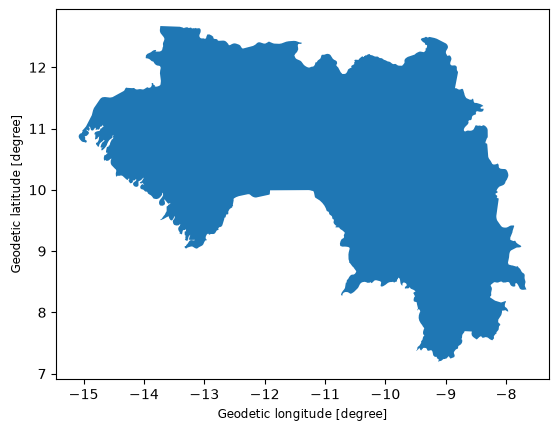

In [4]:
guinea.plot()

## Clip RESOLVE Ecoregions 2017 to Guinea

The `bbox` filter reads only features intersecting Guinea's extent instead of the full ~240 MB shapefile.

In [ ]:
# If you dont have the zip dont worry, just load the already clipped version of RESOLVE
ecoregions = gpd.read_file(f"zip://{ECOREGIONS_ZIP}!Ecoregions2017.shp", bbox=tuple(guinea.total_bounds))
ecoregions = ecoregions.to_crs(guinea.crs)
ecoregions["geometry"] = ecoregions.make_valid()

eco_guinea = gpd.clip(ecoregions, guinea)
eco_guinea = eco_guinea[~eco_guinea.is_empty].explode(index_parts=False).dissolve(by="ECO_NAME", as_index=False, aggfunc="first")
eco_guinea["area_km2"] = eco_guinea.to_crs(eco_guinea.estimate_utm_crs()).area / 1e6

eco_guinea[["ECO_NAME", "BIOME_NAME", "REALM", "area_km2"]].sort_values("area_km2", ascending=False)

,ECO_NAME,BIOME_NAME,REALM,area_km2
0,Guinean forest-savanna,"Tropical & Subtropical Grasslands, Savannas & ...",Afrotropic,135116.890651
3,West Sudanian savanna,"Tropical & Subtropical Grasslands, Savannas & ...",Afrotropic,58766.602612
2,Guinean montane forests,Tropical & Subtropical Moist Broadleaf Forests,Afrotropic,25993.590006
4,Western Guinean lowland forests,Tropical & Subtropical Moist Broadleaf Forests,Afrotropic,21763.210789
1,Guinean mangroves,Mangroves,Afrotropic,2896.414098


## Save

In [4]:
out_path = OUTPUT_DIR / "ecoregions_guinea.gpkg"
eco_guinea.to_file(out_path, layer="ecoregions_guinea", driver="GPKG")
guinea.to_file(out_path, layer="guinea_boundary", driver="GPKG")
print(out_path, f"{out_path.stat().st_size / 1e6:.2f} MB")

/Users/macuser/Documents/UN/projects/Guinea/Guinea_Methodology/studies/output_datasets/ecoregions_guinea.gpkg 0.40 MB


## Import clipped ecoregion

In [6]:
import os
os.getcwd()

'/Users/macuser/Documents/UN/projects/Guinea/Guinea_Methodology/studies'

In [12]:
## Load the clipped version
eco_guinea = gpd.read_file('output_datasets/ecoregions_guinea.gpkg')
eco_guinea

/Users/macuser/Documents/UN/projects/Guinea/Guinea_Methodology/.venv/lib/python3.13/site-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'ecoregions_guinea.gpkg': 'ecoregions_guinea' (default), 'guinea_boundary', 'sentinel2_tiles', 'landsat_wrs2'. Specify layer parameter to avoid this warning.
  result = read_func(


,ECO_NAME,OBJECTID,BIOME_NUM,BIOME_NAME,REALM,ECO_BIOME_,NNH,ECO_ID,SHAPE_LENG,SHAPE_AREA,NNH_NAME,COLOR,COLOR_BIO,COLOR_NNH,LICENSE,area_km2,geometry
0,Guinean forest-savanna,295.0,7.0,"Tropical & Subtropical Grasslands, Savannas & ...",Afrotropic,AF07,4,44,139.987316,55.163098,Nature Imperiled,#FCEE50,#FEAA01,#EE1E23,CC-BY 4.0,135116.890651,"MULTIPOLYGON (((-14.05675 10.10659, -14.06823 ..."
1,Guinean mangroves,296.0,14.0,Mangroves,Afrotropic,AF14,3,113,41.427297,1.934111,Nature Could Recover,#E600AA,#FE01C4,#F9A91B,CC-BY 4.0,2896.414098,"MULTIPOLYGON (((-13.16663 9.0943, -13.10713 9...."
2,Guinean montane forests,297.0,1.0,Tropical & Subtropical Moist Broadleaf Forests,Afrotropic,AF01,3,14,30.830301,2.551486,Nature Could Recover,#304A00,#38A700,#F9A91B,CC-BY 4.0,25993.590006,"MULTIPOLYGON (((-8.21769 7.60474, -8.22263 7.6..."
3,West Sudanian savanna,782.0,7.0,"Tropical & Subtropical Grasslands, Savannas & ...",Afrotropic,AF07,4,62,84.506700,135.539689,Nature Imperiled,#E69800,#FEAA01,#EE1E23,CC-BY 4.0,58766.602612,"MULTIPOLYGON (((-7.8716 9.12002, -8.12471 9.22..."
4,Western Guinean lowland forests,788.0,1.0,Tropical & Subtropical Moist Broadleaf Forests,Afrotropic,AF01,4,30,40.303683,16.716318,Nature Imperiled,#5AA500,#38A700,#EE1E23,CC-BY 4.0,21763.210789,"MULTIPOLYGON (((-8.38062 7.59479, -8.37596 7.5..."


## Satellite tiling grids

## Download and save it 

- **Sentinel-2**: MGRS tiles (109.8 x 109.8 km in UTM) from the official ESA tiling KML. The ESA server drops the
  connection on this 109 MB file, so the identical copy hosted by NASA HLS is used. Each placemark is a polygon plus a
  label point, so only the polygon is kept; the tile's native UTM EPSG is parsed from the description.
- **Landsat**: WRS-2 descending path/row scenes (~185 x 180 km) from USGS.

Both are cached with `pooch` next to the Natural Earth data, and only tiles intersecting Guinea are kept.

In [5]:
import re

GRIDS_CACHE = pooch.os_cache("geodatasets")

s2_kml = pooch.retrieve(
    url="https://hls.gsfc.nasa.gov/wp-content/uploads/2016/03/S2A_OPER_GIP_TILPAR_MPC__20151209T095117_V20150622T000000_21000101T000000_B00.kml",
    known_hash="ffcd58f1443f01f1c6f96baeef83a96239f86b50911729ed12195690ebc4de61",
    path=GRIDS_CACHE,
    fname="sentinel2_tiling_grid.kml",
)
s2 = gpd.read_file(s2_kml, layer="Features", bbox=tuple(guinea.total_bounds))
s2["geometry"] = s2.geometry.apply(lambda g: next(p for p in g.geoms if p.geom_type == "Polygon")).force_2d()
s2["epsg"] = s2["description"].str.extract(r"<b>EPSG</b>.*?<font[^>]*>(\d+)<", flags=re.S)[0].astype(int)
s2_guinea = s2.loc[s2.intersects(guinea.union_all()), ["Name", "epsg", "geometry"]].rename(columns={"Name": "tile_id"})
s2_guinea = s2_guinea.sort_values("tile_id").reset_index(drop=True)

wrs2_zip = pooch.retrieve(
    url="https://d9-wret.s3.us-west-2.amazonaws.com/assets/palladium/production/s3fs-public/atoms/files/WRS2_descending_0.zip",
    known_hash="9e6467f7709999683a41a71f9b0e388b6b84a5f59732ca797c5266c72eb9ce76",
    path=GRIDS_CACHE,
    fname="WRS2_descending.zip",
)
wrs2 = gpd.read_file(wrs2_zip, bbox=tuple(guinea.total_bounds))
wrs2_guinea = wrs2.loc[wrs2.intersects(guinea.union_all()), ["PATH", "ROW", "geometry"]]
wrs2_guinea["path_row"] = wrs2_guinea["PATH"].astype(str).str.zfill(3) + "/" + wrs2_guinea["ROW"].astype(str).str.zfill(3)
wrs2_guinea = wrs2_guinea.sort_values(["PATH", "ROW"]).reset_index(drop=True)

print(f"Sentinel-2 tiles: {len(s2_guinea)} | Landsat WRS-2 path/rows: {len(wrs2_guinea)}")
print("UTM zones:", s2_guinea["epsg"].unique().tolist())

Sentinel-2 tiles: 47 | Landsat WRS-2 path/rows: 21
UTM zones: [32628, 32629]


In [6]:
s2_guinea.to_file(out_path, layer="sentinel2_tiles", driver="GPKG")
wrs2_guinea.to_file(out_path, layer="landsat_wrs2", driver="GPKG")

## Import saved 

Dont need to run the two cells above

In [9]:
## read from gpkg
s2_grid = gpd.read_file('output_datasets/ecoregions_guinea.gpkg', layer='sentinel2_tiles')
landast_grid = gpd.read_file('output_datasets/ecoregions_guinea.gpkg', layer='landsat_wrs2')

In [11]:
s2_grid.head(2)

,tile_id,epsg,geometry
0,28PDS,32628,"POLYGON ((-15.91527 10.85412, -14.9107 10.8554..."
1,28PDT,32628,"POLYGON ((-15.91814 11.75857, -14.91042 11.760..."


## Interactive map

`GeoDataFrame.explore()` renders a Leaflet (JS) map through `folium`.

In [13]:
import folium

m = eco_guinea.explore(
    column="ECO_NAME",
    cmap="tab10",
    tooltip=["ECO_NAME", "BIOME_NAME", "area_km2"],
    style_kwds={"fillOpacity": 0.6, "weight": 1},
    tiles="OpenStreetMap",
    name="Ecoregions",
)
guinea.explore(m=m, color="black", style_kwds={"fill": False, "weight": 2}, name="Guinea boundary")
s2_grid.explore(
    m=m, color="#1f4e9c", tooltip=["tile_id", "epsg"],
    style_kwds={"fillOpacity": 0, "weight": 1.5}, name="Sentinel-2 MGRS tiles",
)
landast_grid.explore(
    m=m, color="#c0392b", tooltip=["path_row"],
    style_kwds={"fillOpacity": 0, "weight": 1.5, "dashArray": "6 4"}, name="Landsat WRS-2 path/row", show=False,
)
folium.LayerControl(collapsed=False).add_to(m)
m

In [25]:
guinea_ecoregions.iloc[2].geometry.geom_type

'MultiPolygon'

## Split ecoregions into single polygons and match satellite tiles

Each ecoregion is a MultiPolygon (e.g. *Guinean montane forests* has 10 disconnected parts). `explode` splits them into
one row per Polygon, and `part_id` numbers the parts within each ecoregion.

For each polygon, its bounding box is intersected with the Sentinel-2 MGRS and Landsat WRS-2 grids. The matching tile
IDs are stored as comma-separated strings, since GeoPackage has no list type (use `.str.split(",")` to get lists back).


In [ ]:
eco_polygons = (
    eco_guinea[["ECO_NAME", "BIOME_NAME", "REALM", "geometry"]]
    .explode(index_parts=False)
    .sort_values("ECO_NAME", kind="stable")
    .reset_index(drop=True)
)
eco_polygons["part_id"] = eco_polygons.groupby("ECO_NAME").cumcount() + 1
eco_polygons["area_km2"] = eco_polygons.to_crs(eco_polygons.estimate_utm_crs()).area / 1e6

bboxes = eco_polygons.envelope
eco_polygons["s2_tiles"] = [",".join(sorted(s2_grid.loc[s2_grid.intersects(b), "tile_id"])) for b in bboxes]
eco_polygons["landsat_tiles"] = [",".join(sorted(landast_grid.loc[landast_grid.intersects(b), "path_row"])) for b in bboxes]
eco_polygons["n_s2_tiles"] = eco_polygons["s2_tiles"].str.count(",") + 1
eco_polygons["n_landsat_tiles"] = eco_polygons["landsat_tiles"].str.count(",") + 1

eco_polygons.drop(columns="geometry")


In [ ]:
polygons_path = OUTPUT_DIR / "ecoregion_polygons.gpkg"
eco_polygons.to_file(polygons_path, layer="ecoregion_polygons", driver="GPKG")
print(polygons_path, len(eco_polygons), "polygons")


## Grid of Guinea

An attempt at splitting Guinea into a regular grid. As a first try, the grid uses 1° x 1° cells in WGS84 (EPSG:4326),
snapped to whole degrees so that cell edges fall on integer latitudes/longitudes. Only cells that intersect Guinea are
kept. `cell_id` is the cell's lower-left corner, e.g. `W014N10`.


In [40]:
import numpy as np
from shapely.geometry import box

GRID_SIZE_DEG = 1.0

guinea = gpd.read_file("output_datasets/ecoregions_guinea.gpkg", layer="guinea_boundary")
minx, miny, maxx, maxy = guinea.total_bounds
xs = np.arange(np.floor(minx / GRID_SIZE_DEG) * GRID_SIZE_DEG, maxx, GRID_SIZE_DEG)
ys = np.arange(np.floor(miny / GRID_SIZE_DEG) * GRID_SIZE_DEG, maxy, GRID_SIZE_DEG)

grid = gpd.GeoDataFrame(
    {
        "cell_id": [f"{'W' if x < 0 else 'E'}{abs(x):03.0f}{'S' if y < 0 else 'N'}{abs(y):02.0f}" for x in xs for y in ys],
        "geometry": [box(x, y, x + GRID_SIZE_DEG, y + GRID_SIZE_DEG) for x in xs for y in ys],
    },
    crs="EPSG:4326",
)
grid = grid[grid.intersects(guinea.union_all())].reset_index(drop=True)
grid["guinea_area_km2"] = grid.intersection(guinea.union_all()).to_crs(grid.estimate_utm_crs()).area / 1e6

print(f"{len(grid)} cells of {GRID_SIZE_DEG}° intersect Guinea")
grid.sort_values("guinea_area_km2").head()


36 cells of 1.0° intersect Guinea


,cell_id,geometry,guinea_area_km2
1,W015N09,"POLYGON ((-14 9, -14 10, -15 10, -15 9, -14 9))",0.211202
35,W008N10,"POLYGON ((-7 10, -7 11, -8 11, -8 10, -7 10))",53.127997
0,W016N10,"POLYGON ((-15 10, -15 11, -16 11, -16 10, -15 ...",122.666567
32,W009N12,"POLYGON ((-8 12, -8 13, -9 13, -9 12, -8 12))",270.795022
12,W012N09,"POLYGON ((-11 9, -11 10, -12 10, -12 9, -11 9))",541.811002


In [37]:
# Testing with 0.5 degree

GRID_SIZE_DEG = 0.5

guinea = gpd.read_file("output_datasets/ecoregions_guinea.gpkg", layer="guinea_boundary")
minx, miny, maxx, maxy = guinea.total_bounds
xs = np.arange(np.floor(minx / GRID_SIZE_DEG) * GRID_SIZE_DEG, maxx, GRID_SIZE_DEG)
ys = np.arange(np.floor(miny / GRID_SIZE_DEG) * GRID_SIZE_DEG, maxy, GRID_SIZE_DEG)

grid5 = gpd.GeoDataFrame(
    {
        "cell_id": [f"{'W' if x < 0 else 'E'}{abs(x):03.0f}{'S' if y < 0 else 'N'}{abs(y):02.0f}" for x in xs for y in ys],
        "geometry": [box(x, y, x + GRID_SIZE_DEG, y + GRID_SIZE_DEG) for x in xs for y in ys],
    },
    crs="EPSG:4326",
)
grid5 = grid[grid.intersects(guinea.union_all())].reset_index(drop=True)
grid5["guinea_area_km2"] = grid.intersection(guinea.union_all()).to_crs(grid.estimate_utm_crs()).area / 1e6

print(f"{len(grid)} cells of {GRID_SIZE_DEG}° intersect Guinea")
grid5.sort_values("guinea_area_km2").head()


113 cells of 0.5° intersect Guinea


,cell_id,geometry,guinea_area_km2
5,W014N10,"POLYGON ((-14 9.5, -14 10, -14.5 10, -14.5 9.5...",0.211202
10,W014N09,"POLYGON ((-13.5 9, -13.5 9.5, -14 9.5, -14 9, ...",13.146986
4,W015N12,"POLYGON ((-14.5 11.5, -14.5 12, -15 12, -15 11...",27.579495
33,W013N12,"POLYGON ((-12.5 12.5, -12.5 13, -13 13, -13 12...",33.446260
112,W008N10,"POLYGON ((-7.5 10, -7.5 10.5, -8 10.5, -8 10, ...",53.127997


In [ ]:
m = guinea.explore(
    color="black", style_kwds={"fill": False, "weight": 2}, tiles="OpenStreetMap", name="Guinea boundary",
)
eco_guinea.explore(
    m=m, column="ECO_NAME", cmap="tab10", tooltip=["ECO_NAME", "area_km2"],
    style_kwds={"fillOpacity": 0.4, "weight": 0.5}, name="Ecoregions", show=False,
)
grid.explore(
    m=m, color="#e67e22", tooltip=["cell_id", "guinea_area_km2"],
    style_kwds={"fillOpacity": 0.05, "weight": 1.5}, name=f"{GRID_SIZE_DEG}° grid",
)
folium.LayerControl(collapsed=False).add_to(m)
m


## H3 hexagon grid of Guinea

An alternative grid using [Uber's H3](https://h3geo.org/) hexagons. Unlike the 1° grid, H3 cells have nearly equal
area everywhere and every neighbour is the same distance away. Resolution 3 (~12,400 km² per cell on average) is used
as a first try because it is comparable to a 1° cell at Guinea's latitude; resolution 4 is ~1,770 km² and resolution 5
~250 km².

`contain="overlap"` keeps every hexagon that touches Guinea, so the border is fully covered (the default would only
keep hexagons whose centre falls inside the country).


In [33]:
import h3
from shapely.geometry import Polygon

H3_RESOLUTION = 3

h3_cells = h3.h3shape_to_cells_experimental(
    h3.geo_to_h3shape(guinea.union_all()), H3_RESOLUTION, contain="overlap"
)
# cell_to_boundary returns (lat, lng) pairs, shapely expects (lng, lat)
h3_grid = gpd.GeoDataFrame(
    {
        "h3_id": h3_cells,
        "geometry": [Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in h3_cells],
    },
    crs="EPSG:4326",
)
h3_grid = h3_grid[h3_grid.intersects(guinea.union_all())].sort_values("h3_id").reset_index(drop=True)
h3_grid["guinea_area_km2"] = h3_grid.intersection(guinea.union_all()).to_crs(h3_grid.estimate_utm_crs()).area / 1e6

print(f"{len(h3_grid)} H3 cells at resolution {H3_RESOLUTION} intersect Guinea")
h3_grid.sort_values("guinea_area_km2").head()


40 H3 cells at resolution 3 intersect Guinea


,h3_id,geometry,guinea_area_km2
19,8354ccfffffffff,"POLYGON ((-13.62058 9.08223, -14.02635 8.65133...",0.016663
26,8354e6fffffffff,"POLYGON ((-14.52328 13.18717, -14.94582 12.730...",6.943785
2,835446fffffffff,"POLYGON ((-8.8175 13.35998, -9.25114 12.92166,...",40.824505
34,8375a3fffffffff,"POLYGON ((-8.73684 7.51121, -9.1426 7.10264, -...",128.717014
36,8375a5fffffffff,"POLYGON ((-7.50619 8.74319, -7.91862 8.33159, ...",179.138022


In [41]:
m = guinea.explore(
    color="black", style_kwds={"fill": False, "weight": 2}, tiles="OpenStreetMap", name="Guinea boundary",
)
eco_guinea.explore(
    m=m, column="ECO_NAME", cmap="tab10", tooltip=["ECO_NAME", "area_km2"],
    style_kwds={"fillOpacity": 0.4, "weight": 0.5}, name="Ecoregions", show=False,
)
grid.explore(
    m=m, color="#e67e22", tooltip=["cell_id", "guinea_area_km2"],
    style_kwds={"fillOpacity": 0.05, "weight": 1.5}, name=f"{GRID_SIZE_DEG}° grid", show=False,
)
grid5.explore(
    m=m, color="#e67e22", tooltip=["cell_id", "guinea_area_km2"],
    style_kwds={"fillOpacity": 0.05, "weight": 1.5}, name=f"{0.5}° grid", show=False,
)
h3_grid.explore(
    m=m, color="#8e44ad", tooltip=["h3_id", "guinea_area_km2"],
    style_kwds={"fillOpacity": 0.05, "weight": 1.5}, name=f"H3 resolution {H3_RESOLUTION}",
)
s2_grid.explore(
    m=m, color="#1f4e9c", tooltip=["tile_id", "epsg"],
    style_kwds={"fillOpacity": 0, "weight": 1.5}, name="Sentinel-2 MGRS tiles",
)
landast_grid.explore(
    m=m, color="#c0392b", tooltip=["path_row"],
    style_kwds={"fillOpacity": 0, "weight": 1.5, "dashArray": "6 4"}, name="Landsat WRS-2 path/row", show=False,
)
folium.LayerControl(collapsed=False).add_to(m)
m
